In [1]:
	# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [21]:
train_dir = "../data/images/images/training/"
test_dir = "../data/images/images/test/"

In [22]:
from pathlib import Path
import matplotlib.image as mpimg

def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    
    # Mencari semua file gambar .jpg di semua subfolder (termasuk day dan night)
    for file in p.rglob('*.jpg'):
        # Mengambil nama folder tempat file gambar itu berada sebagai label (misal: 'day' atau 'night')
        label = file.parent.name 
        
        img = mpimg.imread(file)
        if img is not None:
            img_list.append((img, label))
                    
    return img_list

In [23]:
from pathlib import Path

# Cek path training direktori kamu
p = Path(train_dir)
print("Apakah direktori training ada?", p.exists())

# Cek isi folder di dalamnya
print("Isi folder di dalam training_dir:")
for sub in p.glob('*'):
    print("-", sub.name, "is_dir:", sub.is_dir())
    # Cek jumlah file gambar di dalam subfolder
    jpg_files = list(sub.glob('*.*')) # Ambil semua ekstensi file dulu untuk ngecek
    print(f"  Jumlah file di dalam folder ini: {len(jpg_files)}")

Apakah direktori training ada? True
Isi folder di dalam training_dir:
- day is_dir: True
  Jumlah file di dalam folder ini: 120
- night is_dir: True
  Jumlah file di dalam folder ini: 120


In [24]:
	# Load training data
train_img = load_dataset(train_dir)

In [25]:
	# Check the first data
# It should be a tuple consist of arrays of image and image labels
train_img[0]

(array([[[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [176, 209, 228],
         [177, 210, 229],
         [177, 210, 229]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [180, 213, 232],
         [180, 213, 232],
         [180, 213, 232]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [177, 210, 229],
         [177, 210, 229],
         [177, 210, 229]],
 
        ...,
 
        [[ 35,  40,  43],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 65,  73,  75],
         [ 65,  73,  75],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
         [ 68,  76,  78],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
  

In [26]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 191
(700, 1280, 3)


In [27]:
	# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (700, 1280, 3)
Label	: night


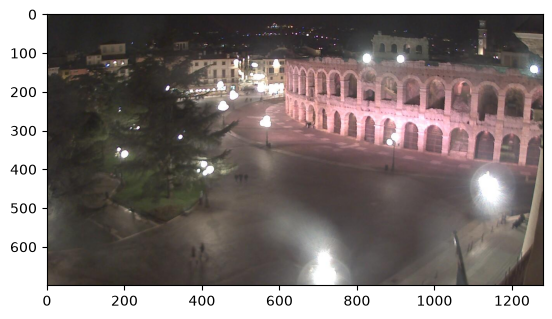

In [28]:
random_img_viz(train_img)

In [29]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

In [34]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))
    
    return std_img_list

In [32]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    
    # Menggunakan rglob agar otomatis masuk ke subfolder (day dan night)
    for file in p.rglob('*.jpg'):
        label = file.parent.name  # Mengambil nama folder ('day' atau 'night') sebagai label
        
        img = mpimg.imread(file)
        if img is not None:
            img_list.append((img, label))
                    
    return img_list

# Load data training dan testing
train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


In [33]:
# 1. Inisialisasi LabelEncoder dari Scikit-Learn
encoder = LabelEncoder()

# Mengambil semua label unik dari data training untuk di-fit
all_train_labels = [item[1] for item in train_img]
encoder.fit(all_train_labels)

# Membuat fungsi label_encoder biar tidak error / garis kuning di VS Code
def label_encoder(label):
    # Mengubah label string ('day'/'night') menjadi angka (0 atau 1)
    return encoder.transform([label])[0]

# 2. Fungsi standardisasi gambar (misalnya normalisasi piksel ke rentang [0, 1])
def standarized_input(image):
    return image / 255.0

NameError: name 'LabelEncoder' is not defined

In [36]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standardized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))
    
    return std_img_list

# Eksekusi preprocessing untuk data train dan test
train_std_img_list = preprocess(train_img)
test_std_img_list = preprocess(test_img)

print("Preprocessing selesai! Total data train siap:", len(train_std_img_list))
print("Contoh label setelah di-encode:", train_std_img_list[0][1])

NameError: name 'label_encoder' is not defined

In [35]:
train_std_img_list = preprocess(train_img)

NameError: name 'label_encoder' is not defined

In [ ]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

In [ ]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

In [ ]:
	# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

In [ ]:
def predict_label(img, threshold):
    # Computer average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1
    
    return pred

In [ ]:
	# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

In [ ]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))
    
    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [ ]:
	# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

In [ ]:
# Evaluate on test data

# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

In [ ]:
	# Create function to extract feature for every images and stored in tabular data
# Stored in Pandas dataframe
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)
    
    # Stack data in columcular way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])


In [ ]:
	# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

In [ ]:
	# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

In [ ]:
	# import requied library
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

In [ ]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')